# Dataset Overview

Inspect generated labels, BirdNET split sizes, and class balance. This notebook reads existing files only.

In [11]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

def find_project_root(start=None):
    path = Path(start or Path.cwd()).resolve()
    for candidate in [path, *path.parents]:
        if (candidate / "workspace").exists() and (candidate / "scripts").exists():
            return candidate
    raise FileNotFoundError("Could not find project root containing workspace/ and scripts/. Run this notebook from inside the StromPetrels project.")

PROJECT_ROOT = find_project_root()
WORKSPACE = PROJECT_ROOT / "workspace"
DATASET = WORKSPACE / "birdnet_dataset"

pd.set_option("display.max_colwidth", 120)
PROJECT_ROOT

WindowsPath('D:/Documents/StromPetrels')

## Generated Manifests

In [12]:
for name in ["download_manifest.csv", "download_files.csv", "labels.csv", "background_labels.csv"]:
    path = WORKSPACE / name
    if path.exists():
        df = pd.read_csv(path)
        print(f"{name}: {len(df):,} rows, {len(df.columns)} columns")
        display(df.head())
    else:
        print(f"Missing: {path}")

download_manifest.csv: 500 rows, 11 columns


,rank,score,species,location,timestamp,recording_file,start_seconds,end_seconds,duration_seconds,label,notes
0,1,1.0,Hydrobates pelagicus_European Storm-Petrel,11,2021-05-22T18:45:04+00:00,011_210522_184504.flac,19197.0,19200.0,55403.406,storm_petrel,NaN
1,2,1.0,Hydrobates pelagicus_European Storm-Petrel,11,2021-05-22T18:45:04+00:00,011_210522_184504.flac,19200.0,19203.0,55403.406,storm_petrel,NaN
2,3,1.0,Hydrobates pelagicus_European Storm-Petrel,11,2021-05-22T18:45:04+00:00,011_210522_184504.flac,22344.0,22347.0,55403.406,storm_petrel,NaN
3,4,1.0,Hydrobates pelagicus_European Storm-Petrel,11,2021-05-22T18:45:04+00:00,011_210522_184504.flac,30792.0,30795.0,55403.406,storm_petrel,NaN
4,5,1.0,Hydrobates pelagicus_European Storm-Petrel,11,2021-05-31T22:11:51+00:00,011_210531_221151.flac,13806.0,13809.0,55403.406,storm_petrel,NaN


download_files.csv: 10 rows, 9 columns


,download_order,recording_file,location,timestamp,detections,best_score,best_rank,first_rank,last_rank
0,1,011_210522_184504.flac,11,2021-05-22T18:45:04+00:00,205,1.000000,1,1,465
1,2,011_210531_221151.flac,11,2021-05-31T22:11:51+00:00,62,1.000000,5,5,470
2,3,011_210709_225044.flac,11,2021-07-09T22:50:44+00:00,114,1.000000,7,7,481
3,4,064_210531_221134.flac,64,2021-05-31T22:11:34+00:00,74,1.000000,11,11,500
4,5,011_210716_213947.flac,11,2021-07-16T21:39:47+00:00,8,0.999999,44,44,482


labels.csv: 500 rows, 10 columns


,clip_id,label,source_file,source_path,clip_path,start_seconds,end_seconds,score,species,split
0,00001_011_210522_184504_0019197000,storm_petrel,011_210522_184504.flac,D:\Documents\StromPetrels\download\data\2021\recordings\011_210522_184504.flac,D:\Documents\StromPetrels\workspace\clips\storm_petrel\00001_011_210522_184504_0019197000.wav,19197.0,19200.0,1.0,Hydrobates pelagicus_European Storm-Petrel,NaN
1,00002_011_210522_184504_0019200000,storm_petrel,011_210522_184504.flac,D:\Documents\StromPetrels\download\data\2021\recordings\011_210522_184504.flac,D:\Documents\StromPetrels\workspace\clips\storm_petrel\00002_011_210522_184504_0019200000.wav,19200.0,19203.0,1.0,Hydrobates pelagicus_European Storm-Petrel,NaN
2,00003_011_210522_184504_0022344000,storm_petrel,011_210522_184504.flac,D:\Documents\StromPetrels\download\data\2021\recordings\011_210522_184504.flac,D:\Documents\StromPetrels\workspace\clips\storm_petrel\00003_011_210522_184504_0022344000.wav,22344.0,22347.0,1.0,Hydrobates pelagicus_European Storm-Petrel,NaN
3,00004_011_210522_184504_0030792000,storm_petrel,011_210522_184504.flac,D:\Documents\StromPetrels\download\data\2021\recordings\011_210522_184504.flac,D:\Documents\StromPetrels\workspace\clips\storm_petrel\00004_011_210522_184504_0030792000.wav,30792.0,30795.0,1.0,Hydrobates pelagicus_European Storm-Petrel,NaN
4,00005_011_210531_221151_0013806000,storm_petrel,011_210531_221151.flac,D:\Documents\StromPetrels\download\data\2021\recordings\011_210531_221151.flac,D:\Documents\StromPetrels\workspace\clips\storm_petrel\00005_011_210531_221151_0013806000.wav,13806.0,13809.0,1.0,Hydrobates pelagicus_European Storm-Petrel,NaN


background_labels.csv: 500 rows, 10 columns


,clip_id,label,source_file,source_path,clip_path,start_seconds,end_seconds,score,species,split
0,background_00001_042_210716_213947_0046346116,Background,042_210716_213947.flac,D:\Documents\StromPetrels\download\data\2021\recordings\042_210716_213947.flac,D:\Documents\StromPetrels\workspace\clips\Background\background_00001_042_210716_213947_0046346116.wav,46346.116,46349.116,NaN,NaN,NaN
1,background_00002_011_210716_213947_0021922986,Background,011_210716_213947.flac,D:\Documents\StromPetrels\download\data\2021\recordings\011_210716_213947.flac,D:\Documents\StromPetrels\workspace\clips\Background\background_00002_011_210716_213947_0021922986.wav,21922.986,21925.986,NaN,NaN,NaN
2,background_00003_064_210531_221134_0016889471,Background,064_210531_221134.flac,D:\Documents\StromPetrels\download\data\2021\recordings\064_210531_221134.flac,D:\Documents\StromPetrels\workspace\clips\Background\background_00003_064_210531_221134_0016889471.wav,16889.471,16892.471,NaN,NaN,NaN
3,background_00004_011_210709_225044_0032181930,Background,011_210709_225044.flac,D:\Documents\StromPetrels\download\data\2021\recordings\011_210709_225044.flac,D:\Documents\StromPetrels\workspace\clips\Background\background_00004_011_210709_225044_0032181930.wav,32181.930,32184.930,NaN,NaN,NaN
4,background_00005_011_210716_213947_0050701349,Background,011_210716_213947.flac,D:\Documents\StromPetrels\download\data\2021\recordings\011_210716_213947.flac,D:\Documents\StromPetrels\workspace\clips\Background\background_00005_011_210716_213947_0050701349.wav,50701.349,50704.349,NaN,NaN,NaN


## BirdNET Dataset Counts

,split,class,count
0,test,Background,75
1,test,storm_petrel,75
2,train,Background,350
3,train,storm_petrel,350
4,validation,Background,75
5,validation,storm_petrel,75


class,Background,storm_petrel
split,,
test,75,75
train,350,350
validation,75,75


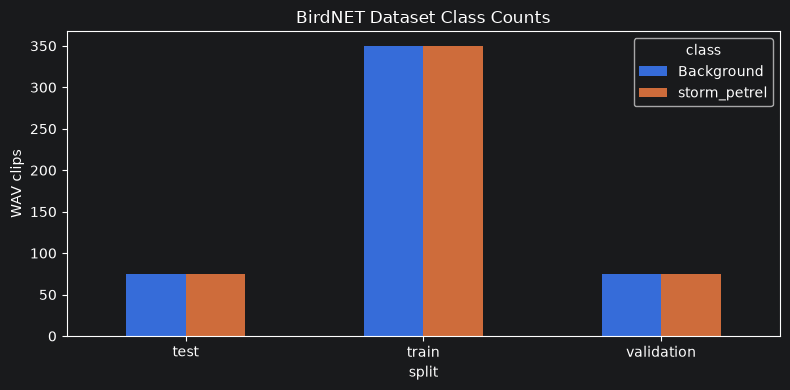

In [13]:
rows = []
for split_dir in sorted(DATASET.glob("*")):
    if not split_dir.is_dir():
        continue
    for class_dir in sorted(split_dir.glob("*")):
        if class_dir.is_dir():
            rows.append({
                "split": split_dir.name,
                "class": class_dir.name,
                "count": len(list(class_dir.glob("*.wav"))),
            })

counts = pd.DataFrame(rows, columns=["split", "class", "count"])
if counts.empty:
    raise FileNotFoundError(f"No WAV clips found under {DATASET}")

display(counts)
pivot = counts.pivot_table(index="split", columns="class", values="count", aggfunc="sum", fill_value=0)
display(pivot)
ax = pivot.plot(kind="bar", figsize=(8, 4), title="BirdNET Dataset Class Counts")
ax.set_ylabel("WAV clips")
ax.set_xlabel("split")
plt.xticks(rotation=0)
plt.tight_layout()